In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\V85_Data_Excluding_14_Cooks_and_Leverage_Points.xlsx"

df = pd.read_excel(file_path)

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (161, 10)


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,57.0,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,33.0,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,43.0,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,48.0,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,36.0,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


In [4]:
# Replace infinity radius with 1500 m

df["Radius of Curve"] = (
    df["Radius of Curve"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        "infinity": "1500",
        "+infinity": "1500",
        "inf": "1500",
        "+inf": "1500",
        "∞": "1500"
    })
)

df["Radius of Curve"] = pd.to_numeric(
    df["Radius of Curve"],
    errors="raise"
)

print("Infinity values remaining:",
      np.isinf(df["Radius of Curve"]).sum())

Infinity values remaining: 0


In [5]:
# Dataset Information
df.info()

# Missing Values
print(df.isnull().sum())

# Descriptive Statistics
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    161 non-null    int64  
 1   V85 Speed             161 non-null    float64
 2   Gradient              161 non-null    float64
 3   Radius of Curve       161 non-null    float64
 4   Carriageway Width     161 non-null    float64
 5   Left Shoulder Width   161 non-null    float64
 6   Left Shoulder Type    161 non-null    str    
 7   Right Shoulder Width  161 non-null    float64
 8   Right Shoulder Type   161 non-null    str    
 9   IRI                   161 non-null    float64
dtypes: float64(7), int64(1), str(2)
memory usage: 12.7 KB
SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
I

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,91.111801,44.792547,4.150804,477.031056,6.349832,0.627081,0.625963,5.958012
std,50.554796,9.617743,2.516367,642.480189,0.874569,0.401504,0.397729,2.667440
min,1.000000,25.000000,0.070000,15.000000,4.700000,0.000000,0.000000,2.150000
25%,50.000000,38.000000,1.900000,35.000000,5.500000,0.400000,0.380000,3.630000
50%,92.000000,44.000000,4.095000,76.000000,7.000000,0.750000,0.750000,5.440000
75%,134.000000,51.550000,6.115000,1500.000000,7.000000,1.000000,1.000000,8.560000
max,175.000000,67.250000,11.085000,1500.000000,8.000000,1.080000,1.050000,12.050000


In [6]:
# Check numerical variables

numeric_cols = [
    "V85 Speed",
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Left Shoulder Width",
    "Right Shoulder Width",
    "IRI"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="raise")

# Identify invalid values
invalid_mask = ~np.isfinite(
    df[numeric_cols].to_numpy(dtype=float)
)

print("Invalid values:", invalid_mask.sum())

if invalid_mask.any():
    display(df.loc[invalid_mask.any(axis=1), numeric_cols])
    raise ValueError("Invalid numerical values remain in the dataset.")

print("All numerical values are finite.")

Invalid values: 0
All numerical values are finite.


In [7]:
df["Left Shoulder Type"] = (
    df["Left Shoulder Type"]
    .str.strip()
    .str.lower()
    .str.capitalize()
)

df["Right Shoulder Type"] = (
    df["Right Shoulder Type"]
    .str.strip()
    .str.lower()
    .str.capitalize()
)

In [8]:
df_encoded = pd.get_dummies(
    df,
    columns=["Left Shoulder Type", "Right Shoulder Type"],
    drop_first=True,
    dtype=int
)

df_encoded.head()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI,Left Shoulder Type_Gravel,Left Shoulder Type_Paved,Right Shoulder Type_Gravel,Right Shoulder Type_Paved
0,1,57.0,1.27,1500.0,5.5,0.9,0.9,3.70,1,0,1,0
1,2,33.0,2.92,46.0,5.5,0.9,0.9,4.51,1,0,1,0
2,3,43.0,7.97,1500.0,5.5,0.9,0.9,4.39,1,0,1,0
3,4,48.0,2.07,1500.0,5.5,0.9,0.9,4.69,1,0,1,0
4,5,36.0,1.21,16.0,5.5,0.9,0.9,5.57,1,0,1,0


In [9]:
df_encoded["Average Shoulder Width"] = (
    df_encoded["Left Shoulder Width"] +
    df_encoded["Right Shoulder Width"]
) / 2

df_encoded[
    [
        "Left Shoulder Width",
        "Right Shoulder Width",
        "Average Shoulder Width"
    ]
].head()

,Left Shoulder Width,Right Shoulder Width,Average Shoulder Width
0,0.9,0.9,0.9
1,0.9,0.9,0.9
2,0.9,0.9,0.9
3,0.9,0.9,0.9
4,0.9,0.9,0.9


In [10]:
shoulder_dummies = [
    col for col in df_encoded.columns
    if col.startswith(
        ("Left Shoulder Type_", "Right Shoulder Type_")
    )
]

X_vif_avg = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        *shoulder_dummies,
        "IRI"
    ]
]

X_vif_avg = X_vif_avg.astype(float)

X_vif_avg_const = sm.add_constant(X_vif_avg)

vif_data_avg = pd.DataFrame()

vif_data_avg["Feature"] = X_vif_avg_const.columns

vif_data_avg["VIF"] = [
    variance_inflation_factor(
        X_vif_avg_const.values, i
    )
    for i in range(X_vif_avg_const.shape[1])
]

vif_data_avg

,Feature,VIF
0,const,103.785440
1,Gradient,1.131163
2,Radius of Curve,1.133241
3,Carriageway Width,1.238302
4,Average Shoulder Width,6.628669
5,Left Shoulder Type_Gravel,6.909818
6,Left Shoulder Type_Paved,6.683297
7,Right Shoulder Type_Gravel,5.879256
8,Right Shoulder Type_Paved,7.561903
9,IRI,1.858186


In [11]:
X_vif_final = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
]

X_vif_final = X_vif_final.astype(float)

X_vif_final_const = sm.add_constant(X_vif_final)

vif_data_final = pd.DataFrame()

vif_data_final["Feature"] = X_vif_final_const.columns

vif_data_final["VIF"] = [
    variance_inflation_factor(
        X_vif_final_const.values, i
    )
    for i in range(X_vif_final_const.shape[1])
]

vif_data_final

,Feature,VIF
0,const,73.987426
1,Gradient,1.083924
2,Radius of Curve,1.071191
3,Carriageway Width,1.160243
4,Average Shoulder Width,1.584971
5,IRI,1.799805


In [12]:
X = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
]

y = df_encoded["V85 Speed"]

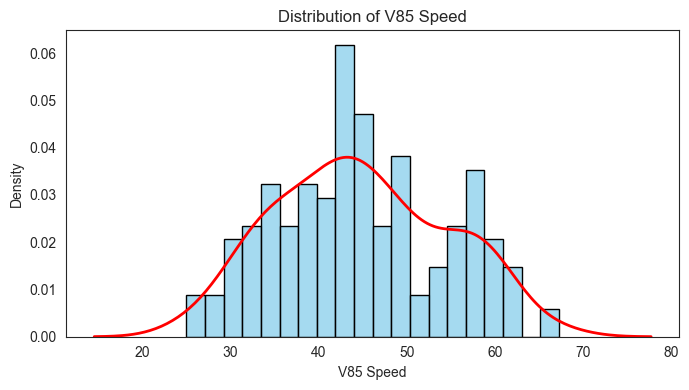

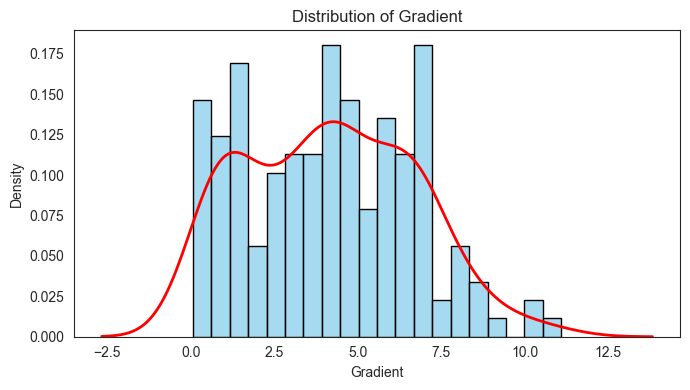

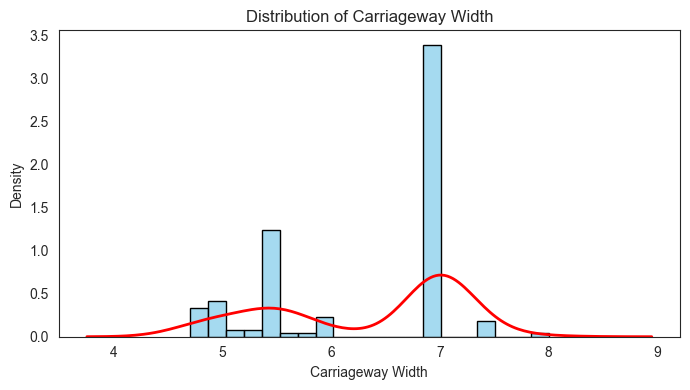

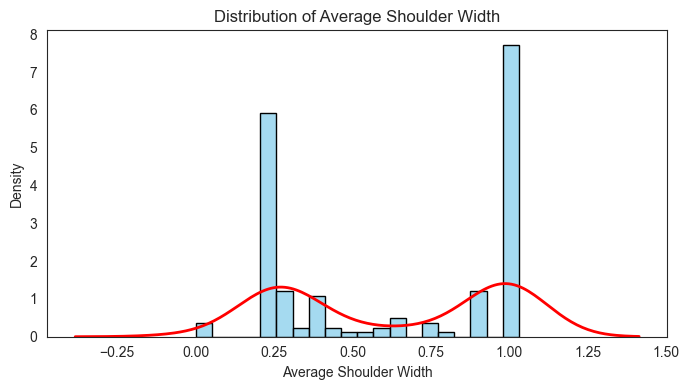

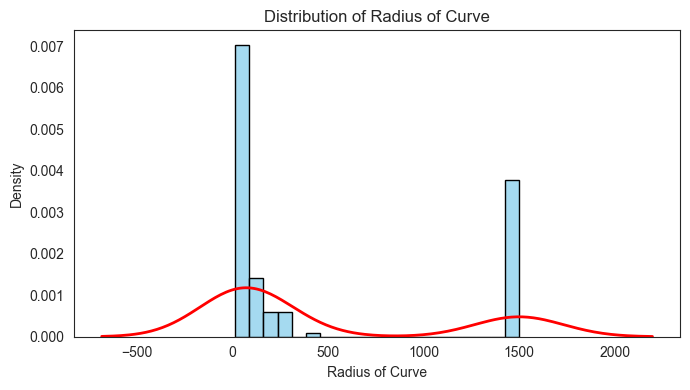

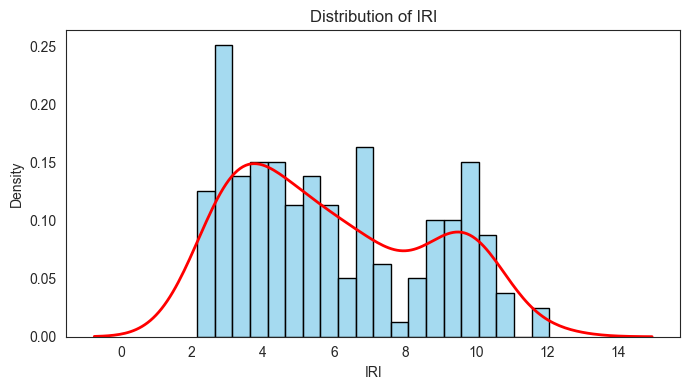

In [13]:
num_cols = [
    "V85 Speed",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "Radius of Curve",
    "IRI"
]

sns.set_style("white")

for col in num_cols:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        df_encoded[col],
        bins=20,
        stat="density",
        color="skyblue",
        edgecolor="black"
    )

    sns.kdeplot(
        df_encoded[col],
        color="red",
        linewidth=2
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

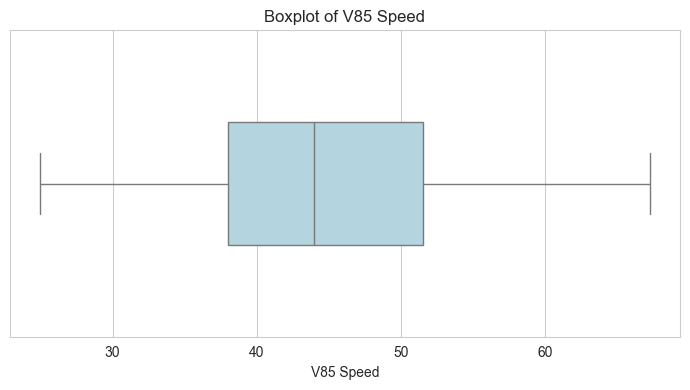

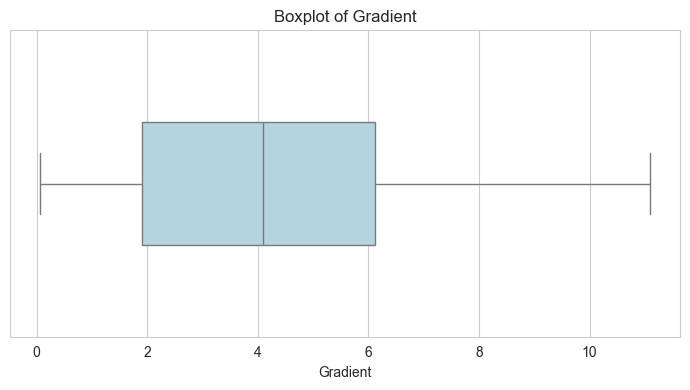

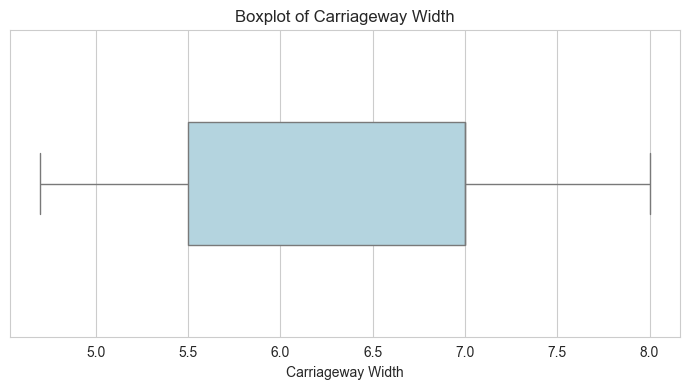

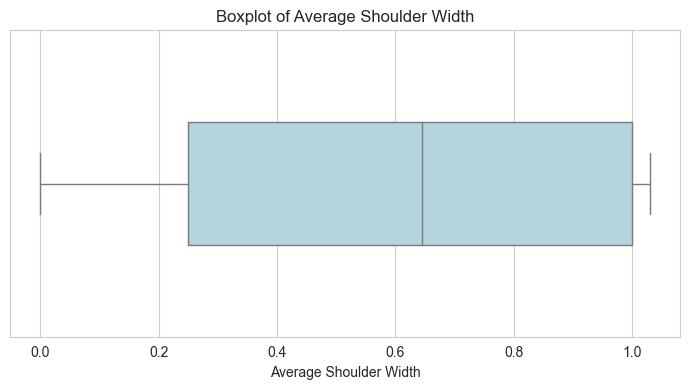

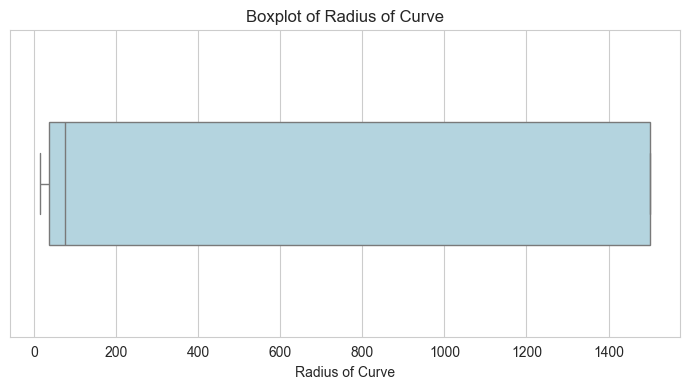

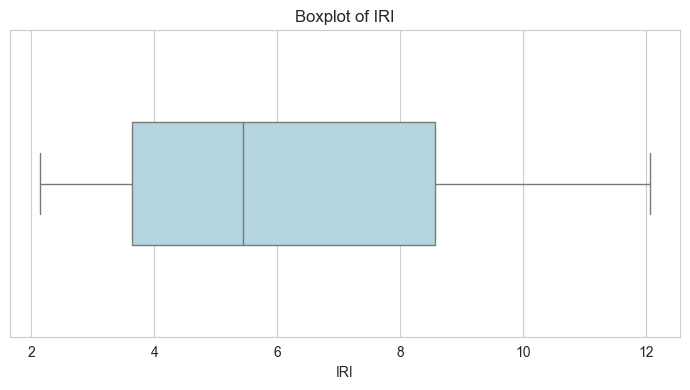

In [14]:
sns.set_style("whitegrid")

for col in num_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x=df_encoded[col],
        color="lightblue",
        width=0.4
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [15]:
skew_table = pd.DataFrame({
    "Variable": num_cols,
    "Skewness": df_encoded[num_cols].skew().values
})

skew_table

,Variable,Skewness
0,V85 Speed,0.162550
1,Gradient,0.215267
2,Carriageway Width,-0.529023
3,Average Shoulder Width,-0.060700
4,Radius of Curve,0.959559
5,IRI,0.404256


,V85 Speed,Gradient,Carriageway Width,Average Shoulder Width,Radius of Curve,IRI
V85 Speed,1.000000,-0.165435,0.133839,-0.204807,0.585816,0.320060
Gradient,-0.165435,1.000000,-0.155119,-0.039003,-0.194135,-0.125282
Carriageway Width,0.133839,-0.155119,1.000000,-0.077547,0.005802,0.322957
Average Shoulder Width,-0.204807,-0.039003,-0.077547,1.000000,-0.090276,-0.587429
Radius of Curve,0.585816,-0.194135,0.005802,-0.090276,1.000000,0.175076
IRI,0.320060,-0.125282,0.322957,-0.587429,0.175076,1.000000


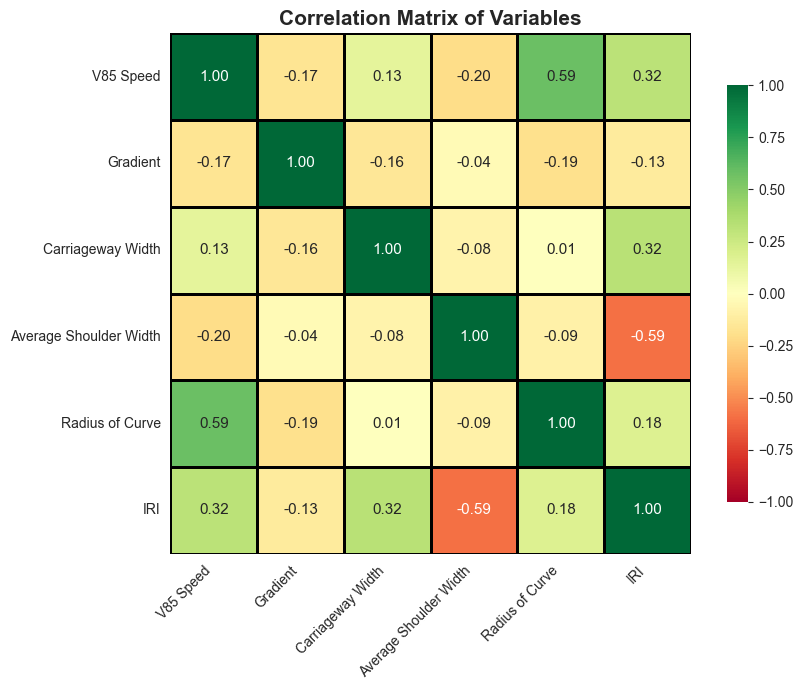

In [16]:
corr_matrix = df_encoded[num_cols].corr()

display(corr_matrix)

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=2,
    linecolor="black",
    square=True,
    annot_kws={"size": 11},
    cbar_kws={"shrink": 0.8}
)

plt.title(
    "Correlation Matrix of Variables",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

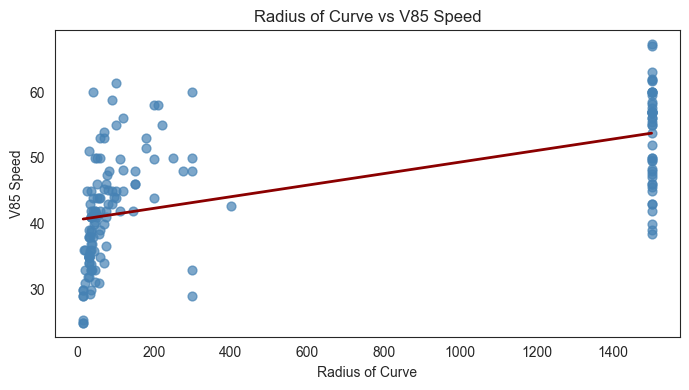

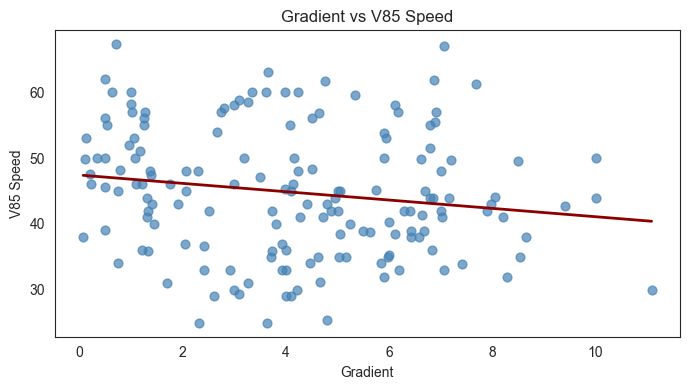

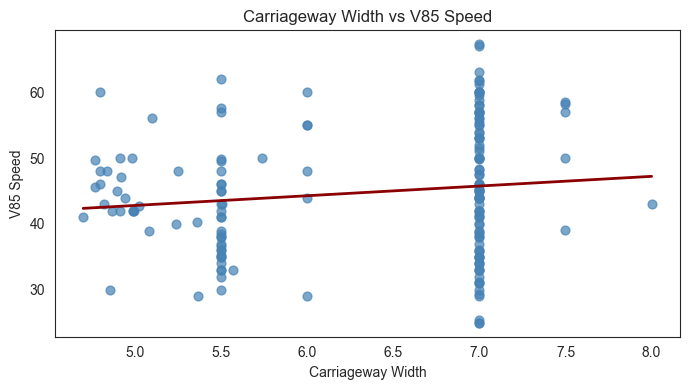

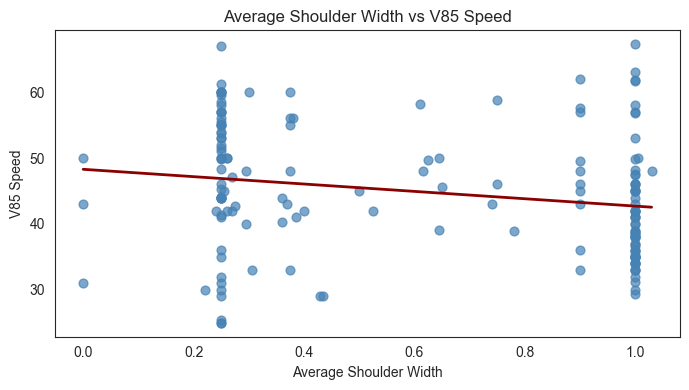

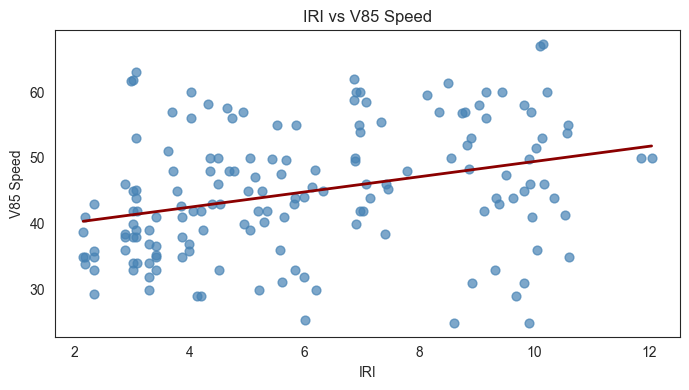

In [17]:
predictor_cols = [
    "Radius of Curve",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

sns.set_style("white")

for col in predictor_cols:
    plt.figure(figsize=(7, 4))

    sns.regplot(
        x=df_encoded[col],
        y=df_encoded["V85 Speed"],
        scatter_kws={
            "s": 40,
            "color": "steelblue",
            "alpha": 0.7
        },
        line_kws={
            "color": "darkred",
            "linewidth": 2
        },
        ci=None
    )

    plt.title(f"{col} vs V85 Speed")
    plt.xlabel(col)
    plt.ylabel("V85 Speed")

    plt.tight_layout()
    plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (128, 5)
X_test shape : (33, 5)
y_train shape: (128,)
y_test shape : (33,)


In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
mlr = LinearRegression()

mlr.fit(X_train, y_train)

mlr

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [21]:
y_train_pred_mlr = mlr.predict(X_train)
y_test_pred_mlr = mlr.predict(X_test)

In [22]:
mlr_train_r2 = r2_score(y_train, y_train_pred_mlr)
mlr_test_r2 = r2_score(y_test, y_test_pred_mlr)

mlr_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_mlr)
)

mlr_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_mlr)
)

mlr_train_mae = mean_absolute_error(
    y_train, y_train_pred_mlr
)

mlr_test_mae = mean_absolute_error(
    y_test, y_test_pred_mlr
)

mlr_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        mlr_train_r2,
        mlr_train_rmse,
        mlr_train_mae
    ],
    "Testing": [
        mlr_test_r2,
        mlr_test_rmse,
        mlr_test_mae
    ]
})

mlr_comparison.round(4)

,Metric,Training,Testing
0,R2,0.3928,0.3922
1,RMSE,7.4950,7.3817
2,MAE,5.9053,5.4447


In [23]:
coef_table_mlr = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": mlr.coef_
})

intercept_row = pd.DataFrame({
    "Variable": ["Constant"],
    "Coefficient": [mlr.intercept_]
})

coef_table_mlr = pd.concat(
    [intercept_row, coef_table_mlr],
    ignore_index=True
)

coef_table_mlr.round(4)

,Variable,Coefficient
0,Constant,32.8377
1,Gradient,-0.1057
2,Radius of Curve,0.0079
3,Carriageway Width,0.8484
4,Average Shoulder Width,-1.7334
5,IRI,0.7903


In [24]:
mlr_final = pd.DataFrame({
    "Model": ["MLR"],
    "R2": [round(mlr_test_r2, 3)],
    "RMSE": [round(mlr_test_rmse, 3)],
    "MAE": [round(mlr_test_mae, 3)]
})

mlr_final

,Model,R2,RMSE,MAE
0,MLR,0.392,7.382,5.445


In [25]:
rf = RandomForestRegressor(
    random_state=42
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [26]:
y_train_pred_rf = rf.predict(X_train)
y_test_pred_rf = rf.predict(X_test)

In [27]:
rf_train_r2 = r2_score(y_train, y_train_pred_rf)
rf_test_r2 = r2_score(y_test, y_test_pred_rf)

rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf)
)

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf)
)

rf_train_mae = mean_absolute_error(
    y_train, y_train_pred_rf
)

rf_test_mae = mean_absolute_error(
    y_test, y_test_pred_rf
)

rf_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        rf_train_r2,
        rf_train_rmse,
        rf_train_mae
    ],
    "Testing": [
        rf_test_r2,
        rf_test_rmse,
        rf_test_mae
    ]
})

rf_comparison.round(4)

,Metric,Training,Testing
0,R2,0.9195,0.6695
1,RMSE,2.7297,5.4431
2,MAE,2.1513,3.8867


In [28]:
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

rf_importance

,Feature,Importance
1,Radius of Curve,0.580112
4,IRI,0.154245
0,Gradient,0.152630
3,Average Shoulder Width,0.067525
2,Carriageway Width,0.045487


In [29]:
rf_final = pd.DataFrame({
    "Model": ["Random Forest"],
    "R2": [round(rf_test_r2, 3)],
    "RMSE": [round(rf_test_rmse, 3)],
    "MAE": [round(rf_test_mae, 3)]
})

rf_final

,Model,R2,RMSE,MAE
0,Random Forest,0.67,5.443,3.887


In [30]:
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [31]:
grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("Tuning Completed")
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", round(grid_rf.best_score_, 3))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Tuning Completed
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score: 0.372


In [32]:
best_rf = grid_rf.best_estimator_

best_rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

In [33]:
best_rf = grid_rf.best_estimator_

best_rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

In [34]:
y_train_pred_rf_tuned = best_rf.predict(X_train)

y_test_pred_rf_tuned = best_rf.predict(X_test)

In [35]:
rf_tuned_train_r2 = r2_score(
    y_train, y_train_pred_rf_tuned
)

rf_tuned_test_r2 = r2_score(
    y_test, y_test_pred_rf_tuned
)

rf_tuned_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf_tuned)
)

rf_tuned_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf_tuned)
)

rf_tuned_train_mae = mean_absolute_error(
    y_train, y_train_pred_rf_tuned
)

rf_tuned_test_mae = mean_absolute_error(
    y_test, y_test_pred_rf_tuned
)

rf_tuned_comparison = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        rf_tuned_train_r2,
        rf_tuned_train_rmse,
        rf_tuned_train_mae
    ],
    "Testing": [
        rf_tuned_test_r2,
        rf_tuned_test_rmse,
        rf_tuned_test_mae
    ]
})

rf_tuned_comparison.round(4)

,Metric,Training,Testing
0,R2,0.8470,0.7055
1,RMSE,3.7617,5.1385
2,MAE,2.9971,3.7804


In [36]:
rf_tuned_final = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "R2": [round(rf_tuned_test_r2, 3)],
    "RMSE": [round(rf_tuned_test_rmse, 3)],
    "MAE": [round(rf_tuned_test_mae, 3)]
})

rf_tuned_final

,Model,R2,RMSE,MAE
0,Tuned Random Forest,0.705,5.139,3.78


In [37]:
# Correlation between IRI and V85 Speed

iri_pearson = df_encoded["IRI"].corr(
    df_encoded["V85 Speed"],
    method="pearson"
)

iri_spearman = df_encoded["IRI"].corr(
    df_encoded["V85 Speed"],
    method="spearman"
)

print("Pearson Correlation:", round(iri_pearson, 4))
print("Spearman Correlation:", round(iri_spearman, 4))

Pearson Correlation: 0.3201
Spearman Correlation: 0.3502


In [38]:
import statsmodels.api as sm

# Fit OLS regression using training data
X_train_const = sm.add_constant(X_train)

ols_model = sm.OLS(
    y_train,
    X_train_const
).fit()

# Display regression summary
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:              V85 Speed   R-squared:                       0.393
Model:                            OLS   Adj. R-squared:                  0.368
Method:                 Least Squares   F-statistic:                     15.78
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           5.74e-12
Time:                        18:02:51   Log-Likelihood:                -439.45
No. Observations:                 128   AIC:                             890.9
Df Residuals:                     122   BIC:                             908.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     32

In [39]:
# Regression Coefficients and Statistical Significance

regression_results = pd.DataFrame({
    "Coefficient": ols_model.params,
    "Std. Error": ols_model.bse,
    "t-value": ols_model.tvalues,
    "p-value": ols_model.pvalues
})

regression_results.round(4)

,Coefficient,Std. Error,t-value,p-value
const,32.8377,6.0137,5.4605,0.0000
Gradient,-0.1057,0.2742,-0.3856,0.7005
Radius of Curve,0.0079,0.0012,6.8136,0.0000
Carriageway Width,0.8484,0.8455,1.0034,0.3176
Average Shoulder Width,-1.7334,2.4804,-0.6988,0.4860
IRI,0.7903,0.3406,2.3202,0.0220


In [40]:
# Detailed Statistical Analysis of IRI

print("IRI Coefficient:",
      round(ols_model.params["IRI"], 4))

print("IRI P-value:",
      round(ols_model.pvalues["IRI"], 4))

print("IRI 95% Confidence Interval:")

print(
    ols_model.conf_int().loc["IRI"]
)

IRI Coefficient: 0.7903
IRI P-value: 0.022
IRI 95% Confidence Interval:
0    0.115997
1    1.464512
Name: IRI, dtype: float64


In [41]:
# Correlation of IRI with Other Variables

iri_correlation = df_encoded[
    [
        "IRI",
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "V85 Speed"
    ]
].corr()

print("Correlation of IRI with Other Variables:")

display(
    iri_correlation[["IRI"]].round(4)
)

Correlation of IRI with Other Variables:


,IRI
IRI,1.0000
Gradient,-0.1253
Radius of Curve,0.1751
Carriageway Width,0.3230
Average Shoulder Width,-0.5874
V85 Speed,0.3201


In [42]:
# OLS Regression with HC3 Robust Standard Errors

ols_robust = ols_model.get_robustcov_results(
    cov_type="HC3"
)

robust_results = pd.DataFrame({
    "Variable": ols_model.params.index,
    "Coefficient": ols_robust.params,
    "Robust Std. Error": ols_robust.bse,
    "Robust t-value": ols_robust.tvalues,
    "Robust p-value": ols_robust.pvalues,
    "CI Lower": ols_robust.conf_int()[:, 0],
    "CI Upper": ols_robust.conf_int()[:, 1]
})

robust_results.round(4)

,Variable,Coefficient,Robust Std. Error,Robust t-value,Robust p-value,CI Lower,CI Upper
0,const,32.8377,6.0864,5.3953,0.0000,20.7891,44.8862
1,Gradient,-0.1057,0.2589,-0.4084,0.6837,-0.6182,0.4068
2,Radius of Curve,0.0079,0.0012,6.5106,0.0000,0.0055,0.0103
3,Carriageway Width,0.8484,0.8009,1.0593,0.2916,-0.7371,2.4338
4,Average Shoulder Width,-1.7334,2.9106,-0.5955,0.5526,-7.4952,4.0284
5,IRI,0.7903,0.3709,2.1305,0.0351,0.0560,1.5245
